<a href="https://colab.research.google.com/github/arabadzhyanzhela-collab/github-lab-2/blob/main/S08%20Miniretos%20Calidad_aire_comentado.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Calidad del aire: predecir el benceno con sensores baratos
**Objetivo:** estimar el benceno real `C6H6(GT)` (caro de medir) a partir de sensores baratos, la temperatura, la humedad y la hora.
Luego probamos 4 «extras» y comparamos con la línea **Base**.

## 1. Librerías
Cargamos todo lo que vamos a usar. Equivale a los `use` / `require` de PHP al principio del fichero.

In [ ]:
import warnings; warnings.filterwarnings("ignore")    # oculta avisos (no errores) para que la salida quede limpia
import pandas as pd, numpy as np, matplotlib.pyplot as plt  # tablas, números y gráficos
from sklearn.impute import SimpleImputer              # rellena huecos (NaN) con la mediana, la media, etc.
from sklearn.pipeline import make_pipeline            # encadena pasos: rellenar -> modelo, como un solo objeto
from sklearn.dummy import DummyRegressor              # modelo "tonto": siempre predice la media (sirve de suelo)
from sklearn.linear_model import LinearRegression     # regresión lineal: suma ponderada de las variables
from sklearn.ensemble import RandomForestRegressor    # bosque aleatorio: media de muchos árboles de decisión
from sklearn.model_selection import train_test_split  # separa entrenamiento/examen al azar
from sklearn.metrics import mean_absolute_error, r2_score  # notas: MAE (error medio, menor = mejor) y R² (1 = perfecto)

## 2. Cargar y limpiar los datos
El CSV usa `;` como separador y `,` como decimal (formato europeo). En este dataset **-200 significa "dato que falta"**, así que lo cambiamos por `NaN`.

In [ ]:
URL = "https://raw.githubusercontent.com/cCoolBoox/IFCD107-alumnado/main/datos/aire_calidad.csv"
df = pd.read_csv(URL, sep=";", decimal=",")            # leemos el CSV europeo
print("Al cargar:", df.shape)                          # (filas, columnas) tal cual viene

df = df.dropna(how="all").loc[:, ~df.columns.str.startswith("Unnamed")]  # fuera filas 100% vacías y columnas basura "Unnamed"
df = df.replace(-200, np.nan)                          # -200 = sensor sin dato -> lo marcamos como hueco (NaN)
print("Después de quitar filas y columnas vacías:", df.shape)

# % de huecos por columna (las 6 peores). Sirve para ver qué columnas son poco fiables.
(df.isna().mean() * 100).round(1).sort_values(ascending=False).head(6).rename("% de datos que faltan")

Al cargar: (9471, 17)
Después de quitar filas y columnas vacías: (9357, 15)


NMHC(GT)         90.2
CO(GT)           18.0
NOx(GT)          17.5
NO2(GT)          17.5
PT08.S2(NMHC)     3.9
C6H6(GT)          3.9
Name: % de datos que faltan, dtype: float64

## 3. Fecha, hora y orden temporal
Unimos `Date` + `Time` en una fecha real, sacamos la **hora** como variable y **ordenamos por tiempo** (imprescindible para el examen temporal).
El gráfico muestra el patrón del tráfico: picos de benceno por la mañana y por la tarde.

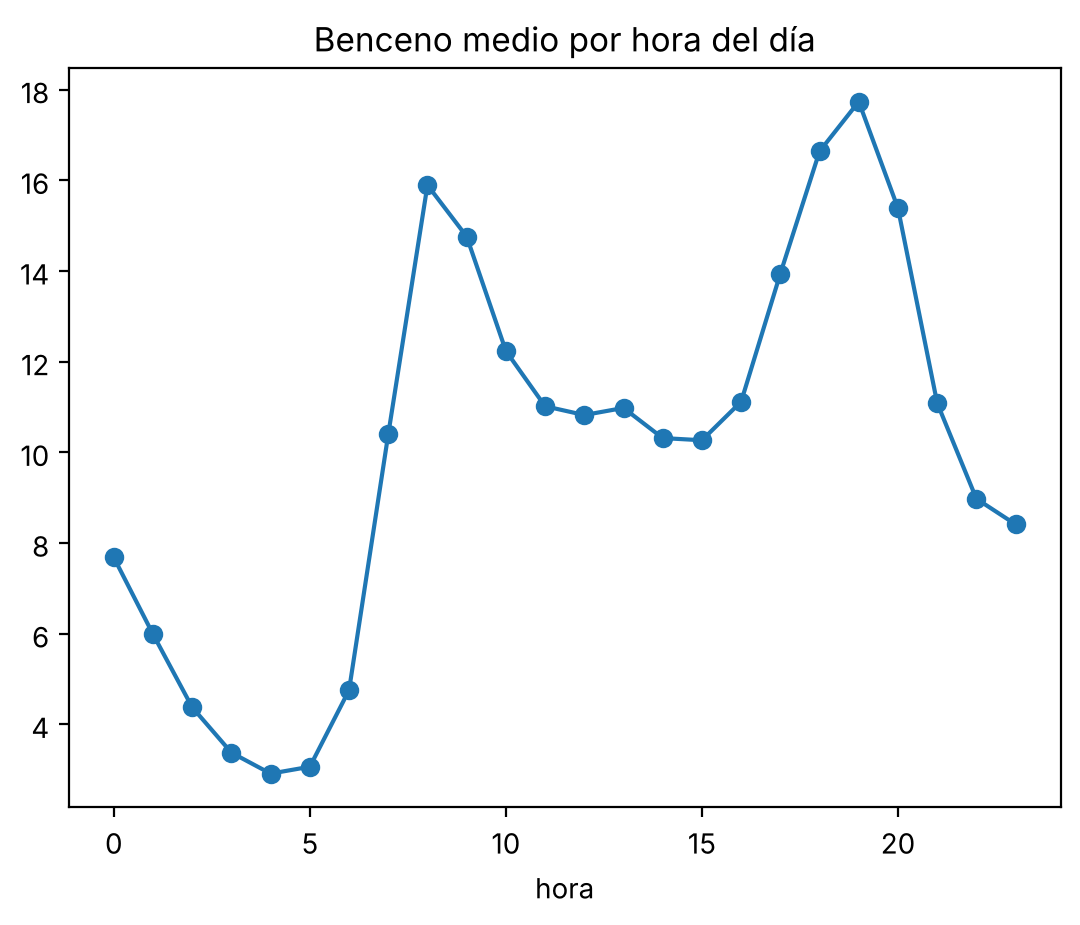

In [ ]:
# "Time" viene como 18.00.00 -> cambiamos los puntos por ":" para que pandas lo entienda como hora
df["momento"] = pd.to_datetime(df["Date"] + " " + df["Time"].str.replace(".", ":", regex=False),
                               format="%d/%m/%Y %H:%M:%S")
df["hora"] = df["momento"].dt.hour                     # nueva variable: hora del día (0-23)
df = df.sort_values("momento").reset_index(drop=True)  # orden cronológico: pasado arriba, futuro abajo

# Benceno medio para cada hora del día
df.groupby("hora")["C6H6(GT)"].mean().plot(marker="o", title="Benceno medio por hora del día")
plt.xlabel("hora"); plt.show()

## 4. Objetivo, variables y correlación
Solo usamos las horas donde el benceno está medido (no se puede aprender sin la respuesta).
La correlación (de -1 a 1) indica cuánto se mueve cada variable junto al benceno.
**Ojo:** `PT08.S2(NMHC)` sale con 0,98, sospechosamente alta.

In [ ]:
objetivo = "C6H6(GT)"                                  # lo que queremos predecir
sensores = ["PT08.S1(CO)", "PT08.S2(NMHC)", "PT08.S3(NOx)", "PT08.S4(NO2)", "PT08.S5(O3)",
            "T", "RH", "AH", "hora"]                   # candidatas a variables de entrada
datos = df.dropna(subset=[objetivo]).copy()            # solo filas con benceno medido; .copy() evita el SettingWithCopyWarning
print(datos[sensores + [objetivo]].corr()[objetivo].round(2).drop(objetivo))  # correlación de cada una con el benceno

PT08.S1(CO)      0.88
PT08.S2(NMHC)    0.98
PT08.S3(NOx)    -0.74
PT08.S4(NO2)     0.77
PT08.S5(O3)      0.87
T                0.20
RH              -0.06
AH               0.17
hora             0.34
Name: C6H6(GT), dtype: float64


## 5. Quitamos el sensor tramposo
Sacamos `PT08.S2(NMHC)` porque está calibrado con el propio benceno: sería como dar al modelo la respuesta (fuga de datos).
`X` = entradas, `y` = respuesta.

In [ ]:
variables = [v for v in sensores if v != "PT08.S2(NMHC)"]  # todas menos la tramposa (como un array_filter en PHP)
X, y = datos[variables], datos[objetivo]
print(len(datos), "horas con benceno medido ·", int(X.isna().sum().sum()),
      "huecos en los sensores hoy (mañana puede haberlos: por eso el Pipeline)")

8991 horas con benceno medido · 0 huecos en los sensores hoy (mañana puede haberlos: por eso el Pipeline)


## 6. Dos formas de hacer el examen
* **Temporal:** entrena con el 80 % más antiguo y examina con el 20 % más reciente. Es lo realista: en la vida real predices el futuro.
* **Al azar:** mezcla horas. Parece mejor, pero hace trampa porque la hora de las 10:00 está en el examen y la de las 9:00 y 11:00 en el entrenamiento.

In [ ]:
corte = int(len(datos) * 0.8)                          # índice donde termina el 80 %
# temporal: pasado -> entrenamiento, futuro -> examen (sin mezclar)
X_tr_t, X_te_t, y_tr_t, y_te_t = X.iloc[:corte], X.iloc[corte:], y.iloc[:corte], y.iloc[corte:]
# al azar: 20 % de examen elegido aleatoriamente (random_state fija la semilla para que salga siempre igual)
X_tr_a, X_te_a, y_tr_a, y_te_a = train_test_split(X, y, test_size=0.2, random_state=42)
print("Temporal: entrena hasta", datos["momento"].iloc[corte - 1].date(),
      "· examen desde", datos["momento"].iloc[corte].date())

Temporal: entrena hasta 2005-01-16 · examen desde 2005-01-16


## 7. El duelo de modelos
Cada modelo va dentro de un **Pipeline**: primero rellena huecos con la mediana y luego predice.
Comparamos 3 modelos con los 2 tipos de examen. El "tonto" es la referencia mínima: un modelo útil tiene que ganarle con claridad.

In [ ]:
modelos = {
    "Siempre la media (tonto)": make_pipeline(SimpleImputer(strategy="median"), DummyRegressor()),
    "Regresión lineal":         make_pipeline(SimpleImputer(strategy="median"), LinearRegression()),
    "Bosque":                   make_pipeline(SimpleImputer(strategy="median"),
                                              RandomForestRegressor(n_estimators=200,     # 200 árboles
                                                                    min_samples_leaf=3,   # cada hoja con ≥3 casos (evita memorizar)
                                                                    random_state=42, n_jobs=2)),
}
filas = {}                                             # aquí guardamos las notas (como un array asociativo de PHP)
for nombre, m in modelos.items():                      # foreach ($modelos as $nombre => $m)
    p_t = m.fit(X_tr_t, y_tr_t).predict(X_te_t)        # entrena con el pasado, predice el futuro
    p_a = m.fit(X_tr_a, y_tr_a).predict(X_te_a)        # entrena y predice con el reparto al azar
    filas[nombre] = {"MAE temporal": mean_absolute_error(y_te_t, p_t), "R² temporal": r2_score(y_te_t, p_t),
                     "MAE al azar":  mean_absolute_error(y_te_a, p_a), "R² al azar":  r2_score(y_te_a, p_a)}
pd.DataFrame(filas).T.round(2)                         # tabla final: una fila por modelo

,MAE temporal,R² temporal,MAE al azar,R² al azar
Siempre la media (tonto),6.07,-0.18,5.84,-0.00
Regresión lineal,1.97,0.86,1.73,0.90
Bosque,2.02,0.85,0.84,0.97


## 8. Modelo final y función para usarlo
Entrenamos el bosque con el pasado y creamos `benceno(...)`, que recibe las lecturas que tengas.
Lo que no pases queda como `NaN` y el Pipeline lo rellena con la mediana: por eso funciona **aunque haya sensores rotos**.

In [ ]:
final = modelos["Bosque"].fit(X_tr_t, y_tr_t)          # modelo definitivo (entrenado con el tramo temporal)

def benceno(**lecturas):                               # **lecturas = argumentos con nombre, como un array asociativo
    fila = pd.DataFrame([{v: lecturas.get(v, np.nan) for v in variables}])  # falta un sensor -> NaN
    return round(float(final.predict(fila)[0]), 1)    # predicción en µg/m³ con 1 decimal

print(benceno(**{"PT08.S1(CO)": 1200, "PT08.S3(NOx)": 900, "PT08.S4(NO2)": 1500, "PT08.S5(O3)": 1000,
                 "T": 15, "RH": 50, "AH": 0.8, "hora": 8}), "µg/m³ con todos los sensores")
print(benceno(**{"PT08.S1(CO)": 1200, "T": 15, "hora": 8}), "µg/m³ con casi todos los sensores rotos")

8.4 µg/m³ con todos los sensores
8.5 µg/m³ con casi todos los sensores rotos


---
# Extras
## Paso 0. Una función que puedas repetir
Para no copiar el bucle del duelo cuatro veces creamos `examen_temporal`: recibe la lista de columnas (y el tipo de relleno) y devuelve la nota del examen temporal.
Es como una función helper en PHP que llamas con parámetros distintos.

In [ ]:
def examen_temporal(columnas, relleno="median"):
    y_examen = datos[objetivo].iloc[corte:]            # respuestas reales del tramo de examen (el futuro)
    for nombre, modelo in {"Lineal": LinearRegression(),
                           "Bosque": RandomForestRegressor(n_estimators=200, min_samples_leaf=3,
                                                           random_state=42, n_jobs=2)}.items():
        m = make_pipeline(SimpleImputer(strategy=relleno), modelo)            # rellenar -> modelo
        m.fit(datos[columnas].iloc[:corte], datos[objetivo].iloc[:corte])     # entrena con el pasado
        p = m.predict(datos[columnas].iloc[corte:])                           # predice el futuro
        print(f"{nombre:7s} MAE {mean_absolute_error(y_examen, p):.2f} · R² {r2_score(y_examen, p):.2f}")

print("Base (lo de siempre):")
examen_temporal(variables)
# La línea «Base» es la referencia (lineal MAE ≈ 1,97 y bosque ≈ 2,02). Cada extra se compara con ella.

Base (lo de siempre):
Lineal  MAE 1.97 · R² 0.86


Bosque  MAE 2.02 · R² 0.85


## Extra 1. Volver a meter `PT08.S2(NMHC)`

In [ ]:
print("Con PT08.S2(NMHC):")
examen_temporal(variables + ["PT08.S2(NMHC)"])
# El bosque sale con R² 1,00 y MAE ≈ 0,01. No te lo creas: ese sensor está calibrado con el propio benceno,
# así que el modelo copia la respuesta. Es una FUGA DE DATOS (data leakage). En la vida real no la tendrías.

Con PT08.S2(NMHC):
Lineal  MAE 1.25 · R² 0.94


Bosque  MAE 0.01 · R² 1.00


## Extra 2. Otro relleno
Primero contamos cuántos huecos llegan de verdad al modelo y luego probamos las tres formas de rellenar.

In [ ]:
print("huecos en las variables de entrada:", int(datos[variables].isna().sum().sum()))
for relleno in ("median", "mean", "constant"):         # mediana, media, o un valor fijo (0)
    print("relleno:", relleno)
    examen_temporal(variables, relleno)
# No cambia nada: hay 0 huecos, así que el relleno no tiene nada que rellenar.
# El Pipeline es un seguro por si mañana llegan datos con huecos (sensores rotos).

huecos en las variables de entrada: 0
relleno: median
Lineal  MAE 1.97 · R² 0.86


Bosque  MAE 2.02 · R² 0.85
relleno: mean
Lineal  MAE 1.97 · R² 0.86


Bosque  MAE 2.02 · R² 0.85
relleno: constant
Lineal  MAE 1.97 · R² 0.86


Bosque  MAE 2.02 · R² 0.85


## Extra 3. Día de la semana

In [ ]:
datos["dia_semana"] = datos["momento"].dt.dayofweek    # 0 = lunes … 6 = domingo
examen_temporal(variables + ["dia_semana"])
# Apenas cambia (lineal ≈ 1,93, bosque ≈ 2,04). Los sensores ya "ven" el tráfico,
# así que el ciclo semanal ya está dentro de sus lecturas.

Lineal  MAE 1.93 · R² 0.86


Bosque  MAE 2.04 · R² 0.84


## Extra 4. Quitar la hora

In [ ]:
examen_temporal([v for v in variables if v != "hora"])
# Sale casi igual (lineal ≈ 1,98, bosque ≈ 2,09). La hora es redundante: los sensores ya reflejan
# el ritmo del día. Se puede quitar y el modelo queda más simple casi sin perder precisión.

Lineal  MAE 1.98 · R² 0.86


Bosque  MAE 2.09 · R² 0.84


---
# Hoja del equipo

| Prueba | Lineal (MAE · R²) | Bosque (MAE · R²) | Conclusión |
|---|---|---|---|
| **Base** | 1,97 · 0,86 | 2,02 · 0,85 | Referencia. |
| **Extra 1:** + PT08.S2(NMHC) | 1,25 · 0,94 | 0,01 · 1,00 | Trampa (fuga de datos). |
| **Extra 2:** relleno median / mean / constant | 1,97 · 0,86 | 2,02 · 0,85 | Igual: no hay huecos. |
| **Extra 3:** + día de la semana | 1,93 · 0,86 | 2,04 · 0,84 | Casi igual. |
| **Extra 4:** sin hora | 1,98 · 0,86 | 2,09 · 0,84 | Casi igual, modelo más simple. |

**Extra 1.** Al meter PT08.S2 el bosque saca R² 1,00 y MAE 0,01, pero no me lo creo porque ese sensor está calibrado con el benceno: el modelo copia la respuesta (fuga de datos).

**Extra 2.** Con mediana, media o constante sale exactamente lo mismo porque en las variables de entrada hay 0 huecos; el relleno solo es un seguro para cuando falle algún sensor.

**Extra 3.** Añadir el día de la semana casi no cambia nada (lineal 1,97 → 1,93, bosque 2,02 → 2,04) porque los sensores ya captan el ciclo semanal del tráfico.

**Extra 4.** Quitar la hora casi no empeora (lineal 1,98, bosque 2,09) porque es información redundante con los sensores; se puede quitar para tener un modelo más simple.

**Duelo (temporal vs. al azar).** Al azar el bosque parece mucho mejor (MAE 0,84 · R² 0,97) que en el examen temporal (MAE 2,02 · R² 0,85): mezclar horas vecinas le deja "ver" el futuro. Nos quedamos con el temporal porque es el realista. Ambos modelos ganan con claridad al tonto (MAE 6,07).

**Conclusión general:** la regresión lineal y el bosque empatan (≈ 2 µg/m³ de error) con el examen temporal, que es el honesto. Ninguna variable extra legítima mejora el modelo de forma clara.